# Prompts as governed, tested software

**Course** MLAIDP · **Module 4 — Prompt Engineering and Governance**
· **When:** after slide 42 (*Deployment and rollback procedures*), before slide 43 (*Quality assurance framework
overview*); §1 can also run on its own after slide 21 (*Lesson Summary and Key Takeaways*)
· **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain), us-east-1
· **Runtime** about 1.5–2 minutes of cell time (incl. §0 Prep and cleanup) · **Cost per run** under $0.01

**What you'll learn**
- Score four prompt techniques — **zero-shot, few-shot, chain-of-thought, structured output through a forced tool
  schema** — on a golden set with Wilson intervals, tokens and $ per 1,000 requests, and see that the best technique
  depends on the model.
- Treat a prompt as a resource in **Amazon Bedrock Prompt Management**: variants (one per model), immutable numbered
  versions, content-addressed publishing that is safe to re-run, and Converse called with a **prompt version ARN**.
- Define an **Amazon Bedrock Flow in code** — prompt node → Lambda (rules + CRM) → condition → specialist prompts —
  publish a flow **version** behind an **alias**, and read the per-node trace of every invocation.
- Release a "harmless" prompt edit, catch the regression with the golden set, and **roll back by moving the alias**.

> **Resources:** IAM roles `mlaidp2-m04-flow-role` and `mlaidp2-m04-crm-role`, Lambda `mlaidp2-m04-crm`, five
> prompts `mlaidp2-m04-*`, flow `mlaidp2-m04-support-flow` with alias `live`. §0 Prep creates the roles in about
> 20 s; everything else is created in the sections where it is explained. The cleanup section deletes it all.

## §0 Setup

In [1]:
import sys, json, hashlib, math, re, time
from concurrent.futures import ThreadPoolExecutor

sys.path.insert(0, "../common")
import mlaidp as m
from botocore.exceptions import ClientError

RID = m.setup_banner("M04")
bedrock = m.client("bedrock-runtime")              # model calls (Converse)
agent = m.client("bedrock-agent")                  # control plane: Prompt Management, Flows
agent_rt = m.client("bedrock-agent-runtime")       # InvokeFlow
lam, iam = m.client("lambda"), m.client("iam")

P = "mlaidp2-m04"
FLOW, ALIAS, FN = f"{P}-support-flow", "live", f"{P}-crm"
FLOW_ROLE, FN_ROLE = f"{P}-flow-role", f"{P}-crm-role"
ACCOUNT, REGION = m.account(), m.REGION

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 10225e91


## §0 Prep — IAM roles (about 20 s, idempotent)
Two roles: the flow's execution role (its permissions are set in §3, scoped to the exact prompts and the Lambda) and
the Lambda's role (logs only). A new role needs a few seconds before a service can assume it.

In [2]:
def ensure_role(name: str, service: str) -> str:
    trust = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Principal": {"Service": service},
             "Action": "sts:AssumeRole", "Condition": {"StringEquals": {"aws:SourceAccount": ACCOUNT}}}]}
    try:
        return iam.get_role(RoleName=name)["Role"]["Arn"]
    except ClientError:
        arn = iam.create_role(RoleName=name, AssumeRolePolicyDocument=json.dumps(trust),
                              Tags=[{"Key": k, "Value": v} for k, v in m.TAGS.items()])["Role"]["Arn"]
        time.sleep(10)                                     # IAM propagation
        return arn

FLOW_ROLE_ARN = ensure_role(FLOW_ROLE, "bedrock.amazonaws.com")
FN_ROLE_ARN = ensure_role(FN_ROLE, "lambda.amazonaws.com")
LOGS_ONLY = {"Version": "2012-10-17", "Statement": [
    {"Effect": "Allow", "Action": ["logs:CreateLogGroup", "logs:CreateLogStream", "logs:PutLogEvents"],
     "Resource": f"arn:aws:logs:{REGION}:{ACCOUNT}:log-group:/aws/lambda/{FN}*"}]}
iam.put_role_policy(RoleName=FN_ROLE, PolicyName="logs", PolicyDocument=json.dumps(LOGS_ONLY))
print(m.masked(FLOW_ROLE_ARN), "\n" + m.masked(FN_ROLE_ARN))

arn:aws:iam::123456789012:role/mlaidp2-m04-flow-role 
arn:aws:iam::123456789012:role/mlaidp2-m04-crm-role


## 1 · Prompt techniques, measured (slides 11–20)
The task is the first step of the support workflow on slide 35: **triage** a customer message to BILLING, TECHNICAL,
GENERAL — or CLARIFY when the customer disputes a payment without giving an order number (slide 15). Eighteen golden
messages with a known right answer, including the traps: several topics in one message, decoy ids (a claim number,
a policy number), a premium question that is *not* a dispute.

In [3]:
GOLDEN = [  # (message, expected route) - items are numbered from 0 in every table below
    ("Hi, I paid my premium twice for order ORD-50731 this month. Can I get the second payment of 64 USD back?", "BILLING"),
    ("This is ridiculous!!! ORD-48810: the app crashes every time I upload my photos, you charged me 240 USD twice, "
     "and honestly I want to cancel the whole thing.", "BILLING"),
    ("You took money from my account twice. Fix it.", "CLARIFY"),
    ("The app logs me out every time I try to upload the photos of my car.", "TECHNICAL"),
    ("Does my home policy cover a burst pipe in the kitchen?", "GENERAL"),
    ("I can't reset my password on the website, the link in the email has expired.", "TECHNICAL"),
    ("How do I make a claim for hail damage to my roof?", "GENERAL"),
    ("Why did my monthly premium go up from 64 to 71 USD?", "BILLING"),
    ("Please refund the 120 USD you charged on 3 October, it was a mistake.", "CLARIFY"),
    ("Refund ORD-61234 please, the 35 USD charge was wrong. Also your website is really slow.", "BILLING"),
    ("I want to cancel my car insurance at the end of the month.", "BILLING"),
    ("The upload button for documents is greyed out in the app. My claim number is CLM-88812.", "TECHNICAL"),
    ("My order number is ORD-77120. When will the adjuster visit to look at the damage?", "GENERAL"),
    ("Great service last week, thank you! Just wanted to say that.", "GENERAL"),
    ("There is a charge of 89 USD on my card I don't recognise, and I also can't log in to the app anymore.", "CLARIFY"),
    ("Can I pay my premium by bank transfer instead of card?", "BILLING"),
    ("My card was charged for ORD-50731 but the website says the payment failed.", "BILLING"),
    ("What is the deductible on my home policy HP-2291?", "GENERAL"),
]
LABELS = ("BILLING", "TECHNICAL", "GENERAL", "CLARIFY")
print({lab: sum(e == lab for _, e in GOLDEN) for lab in LABELS})

{'BILLING': 7, 'TECHNICAL': 3, 'GENERAL': 5, 'CLARIFY': 3}


Every technique gets **the same definitions and rules** — only the technique changes, so the comparison is fair.

In [4]:
TOPICS = """Topics: BILLING = payments, premiums, refunds, charges, cancelling or ending a policy. TECHNICAL = the app, the website,
logging in, uploading photos or documents. GENERAL = everything else, including cover questions and claims."""
DISPUTE = """the customer says a payment or charge already made is wrong, duplicated or unknown, or wants money back
(questions about prices, premiums or payment methods are not disputes)"""
RULES = f"""You triage messages to AnyCompany Insurance's support desk.
{TOPICS}
Rules: (1) money first: if any part of the message is BILLING, the label is BILLING. (2) if {DISPUTE}
and no order number (format ORD-12345) is given, the label is CLARIFY instead, so we can ask for it."""
ASK = "Answer with one label only: BILLING, TECHNICAL, GENERAL or CLARIFY.\n\nMessage: {msg}"

ZERO_SHOT = RULES + "\n" + ASK
FEW_SHOT = RULES + """
Examples:
Message: I was charged 50 USD twice for ORD-11111, please refund one. -> BILLING
Message: Refund my last payment, it was wrong. -> CLARIFY
Message: The website shows an error when I upload my driving licence. -> TECHNICAL
Message: Is my bicycle covered when it is stolen from the garden? -> GENERAL
Message: The app is broken and you also charged me twice for something, I have no idea what. -> CLARIFY
Message: How much is the premium if I add my daughter to the car policy? -> BILLING
""" + ASK
CHAIN_OF_THOUGHT = RULES + """
Think step by step before you answer: 1. list every topic in the message; 2. apply rule 1; 3. apply rule 2: is a payment
disputed, and is there an order number? Then write the final line exactly as LABEL: <label>.

Message: {msg}"""

The fourth technique changes the **division of labour**: the model only *describes* the message through a JSON
schema (forced `toolChoice`, the reliable way to get structured output from Nova), and **code applies the rules**.
Rules in code are deterministic, unit-testable and auditable — the model does what it is good at: reading.

In [5]:
TRIAGE_TOOL = {"toolSpec": {"name": "record_triage", "description": "Record the facts of a support message.",
    "inputSchema": {"json": {"type": "object", "required": ["topics", "disputes_payment", "order_id"], "properties": {
        "topics": {"type": "array", "items": {"enum": ["BILLING", "TECHNICAL", "GENERAL"]}},
        "disputes_payment": {"type": "boolean", "description": "true only if " + " ".join(DISPUTE.split())},
        "order_id": {"type": ["string", "null"],
                     "description": "order number in the format ORD-12345, null if absent"}}}}}}
DESCRIBE = f"""You record the facts of messages to AnyCompany Insurance's support desk.
{TOPICS}
Record every topic in the message.

Message: {{msg}}"""
ORDER_ID = re.compile(r"ORD-\d{5}")

def decide(facts: dict) -> str:
    """The routing rules - the same lines run in the flow's Lambda in §3."""
    topics = [str(t).upper() for t in facts.get("topics") or []] or ["GENERAL"]
    order_id = facts.get("order_id") if ORDER_ID.fullmatch(str(facts.get("order_id"))) else None
    if "BILLING" in topics:                                                    # rule 1: money first
        return "CLARIFY" if facts.get("disputes_payment") and not order_id else "BILLING"   # rule 2
    return topics[0] if topics[0] in ("TECHNICAL", "GENERAL") else "GENERAL"

assert decide({"topics": ["TECHNICAL", "BILLING"], "disputes_payment": True, "order_id": None}) == "CLARIFY"
assert decide({"topics": ["BILLING"], "disputes_payment": True, "order_id": "ORD-12345"}) == "BILLING"
print(json.dumps(TRIAGE_TOOL["toolSpec"]["inputSchema"]["json"]["properties"], indent=1)[:500])

{
 "topics": {
  "type": "array",
  "items": {
   "enum": [
    "BILLING",
    "TECHNICAL",
    "GENERAL"
   ]
  }
 },
 "disputes_payment": {
  "type": "boolean",
  "description": "true only if the customer says a payment or charge already made is wrong, duplicated or unknown, or wants money back (questions about prices, premiums or payment methods are not disputes)"
 },
 "order_id": {
  "type": [
   "string",
   "null"
  ],
  "description": "order number in the format ORD-12345, null if absent"


One function per call, one grader per technique: the first word for zero/few-shot, the `LABEL:` line for
chain-of-thought, the rules in code for the structured technique.

In [6]:
def triage(model_id: str, technique: str, msg: str) -> dict:
    kw = dict(modelId=model_id, inferenceConfig={"maxTokens": 600, "temperature": 0})
    t0 = time.perf_counter()
    if technique == "structured":
        forced = {"tools": [TRIAGE_TOOL], "toolChoice": {"tool": {"name": "record_triage"}}}
        r = bedrock.converse(messages=[{"role": "user", "content": [{"text": DESCRIBE.format(msg=msg)}]}],
                             toolConfig=forced, **kw)
        facts = next(c["toolUse"]["input"] for c in r["output"]["message"]["content"] if "toolUse" in c)
        label, raw = decide(facts), json.dumps(facts)
    else:
        template = {"zero-shot": ZERO_SHOT, "few-shot": FEW_SHOT, "chain-of-thought": CHAIN_OF_THOUGHT}[technique]
        r = bedrock.converse(messages=[{"role": "user", "content": [{"text": template.format(msg=msg)}]}], **kw)
        raw = m.text_of(r)
        found = re.findall(r"\b(BILLING|TECHNICAL|GENERAL|CLARIFY)\b", raw)
        label = (found[-1] if technique == "chain-of-thought" else raw.split()[0].strip(".:*")) if found else None
    return {"label": label, "raw": raw, "ms": (time.perf_counter() - t0) * 1000, "usage": r["usage"],
            "usd": m.usd(model_id, r["usage"])}

print(triage(m.NOVA_MICRO, "structured", GOLDEN[2][0]))

{'label': 'CLARIFY', 'raw': '{"disputes_payment": true, "topics": ["BILLING"], "order_id": null}', 'ms': 665.9674169495702, 'usage': {'inputTokens': 597, 'outputTokens': 32, 'totalTokens': 629}, 'usd': 2.5374999999999993e-05}


Four techniques × two models × 18 messages = 144 calls, four at a time.

In [7]:
TECHNIQUES = ["zero-shot", "few-shot", "chain-of-thought", "structured"]
MODELS = [m.NOVA_MICRO, m.NOVA_LITE]

def run_case(case):
    model_id, technique, i = case
    msg, expected = GOLDEN[i]
    try:
        r = triage(model_id, technique, msg)
    except ClientError as e:
        r = {"label": m.error_code(e), "raw": "", "ms": None, "usage": {}, "usd": 0.0}
    return {"model": model_id, "technique": technique, "item": i, "ok": r["label"] == expected, **r}

t0 = time.time()
with ThreadPoolExecutor(4) as pool:
    cases = [(mo, t, i) for mo in MODELS for t in TECHNIQUES for i in range(len(GOLDEN))]
    TRIAGE_RUNS = list(pool.map(run_case, cases))
print(f"{len(TRIAGE_RUNS)} calls in {time.time() - t0:.0f} s")

144 calls in 23 s


### The scorecard
*n* = 18, so every accuracy comes with a **Wilson 95 % interval**. Tokens and $ per 1,000 requests are measured from
the `usage` block of each response.

In [8]:
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    p, d = k / n, 1 + z * z / n
    centre, half = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, centre - half), min(1.0, centre + half)

def median(xs):
    xs = sorted(x for x in xs if x is not None)
    return xs[len(xs) // 2] if xs else None

SCORE = []
for mo in MODELS:
    for t in TECHNIQUES:
        rs = [r for r in TRIAGE_RUNS if r["model"] == mo and r["technique"] == t]
        k = sum(r["ok"] for r in rs); lo, hi = wilson(k, len(rs))
        SCORE.append({"model": m.model_name(mo), "technique": t, "correct": f"{k}/{len(rs)}", "acc": k / len(rs),
                      "95% CI": f"{lo:.0%}–{hi:.0%}",
                      "in tok": sum(r["usage"].get("inputTokens", 0) for r in rs) / len(rs),
                      "out tok": sum(r["usage"].get("outputTokens", 0) for r in rs) / len(rs),
                      "p50 ms": median(r["ms"] for r in rs), "$ / 1k": 1000 * sum(r["usd"] for r in rs) / len(rs),
                      "missed": " ".join(str(r["item"]) for r in rs if not r["ok"])})
m.table(SCORE, fmt={"acc": "{:.0%}", "in tok": "{:.0f}", "out tok": "{:.0f}", "p50 ms": "{:.0f}", "$ / 1k": "${:.4f}"})

model,technique,correct,acc,95% CI,in tok,out tok,p50 ms,$ / 1k,missed
Nova Micro,zero-shot,14/18,78%,55%–91%,198,34,514,$0.0116,0 2 8 15
Nova Micro,few-shot,11/18,61%,39%–80%,328,23,417,$0.0147,0 1 7 9 10 15 16
Nova Micro,chain-of-thought,15/18,83%,61%–94%,240,195,979,$0.0357,2 7 12
Nova Micro,structured,16/18,89%,67%–97%,606,34,488,$0.0260,7 10
Nova Lite,zero-shot,18/18,100%,82%–100%,198,6,404,$0.0132,
Nova Lite,few-shot,17/18,94%,74%–99%,328,38,656,$0.0288,1
Nova Lite,chain-of-thought,17/18,94%,74%–99%,240,97,872,$0.0377,12
Nova Lite,structured,17/18,94%,74%–99%,606,34,632,$0.0447,10


### Which differences are real?
Same 18 messages for every arm → compare **paired** (McNemar exact: only the messages where two arms disagree count).

In [9]:
def mcnemar(a: list[bool], b: list[bool]) -> tuple[int, int, float]:
    only_a = sum(x and not y for x, y in zip(a, b)); only_b = sum(y and not x for x, y in zip(a, b))
    n, k = only_a + only_b, min(only_a, only_b)
    return only_a, only_b, min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n) if n else 1.0

def oks(model_id, technique):
    rs = sorted(TRIAGE_RUNS, key=lambda r: r["item"])
    return [r["ok"] for r in rs if r["model"] == model_id and r["technique"] == technique]

rows = []
for mo in MODELS:
    for t in TECHNIQUES[1:]:
        a_only, b_only, p = mcnemar(oks(mo, t), oks(mo, "zero-shot"))
        rows.append([m.model_name(mo), f"{t} vs zero-shot", f"+{a_only} / −{b_only}", f"{p:.2f}",
                     "✓ real difference" if p < 0.05 else "✗ not separable with n = 18"])
m.table(rows, ["Model", "Comparison", "fixed / broke", "McNemar p", "Verdict"])

Model,Comparison,fixed / broke,McNemar p,Verdict
Nova Micro,few-shot vs zero-shot,+2 / −5,0.45,✗ not separable with n = 18
Nova Micro,chain-of-thought vs zero-shot,+3 / −2,1.00,✗ not separable with n = 18
Nova Micro,structured vs zero-shot,+4 / −2,0.69,✗ not separable with n = 18
Nova Lite,few-shot vs zero-shot,+0 / −1,1.00,✗ not separable with n = 18
Nova Lite,chain-of-thought vs zero-shot,+0 / −1,1.00,✗ not separable with n = 18
Nova Lite,structured vs zero-shot,+0 / −1,1.00,✗ not separable with n = 18


One picture: accuracy (with its interval) against cost. The cheapest arm whose interval overlaps the best one is the
candidate for production — **after** a larger evaluation (Module 9).

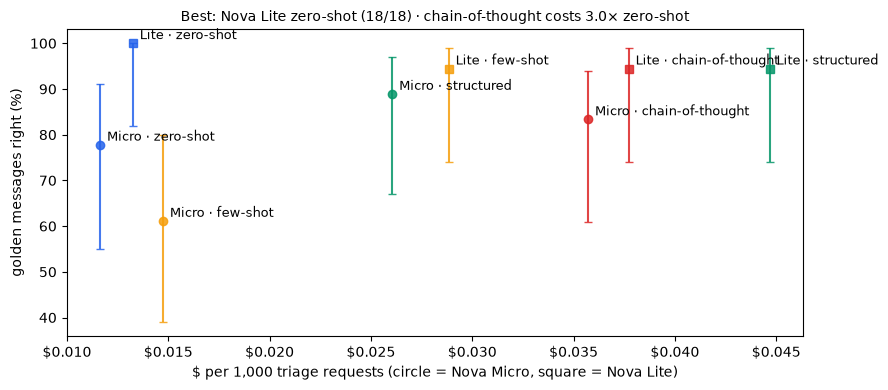

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"zero-shot": "#2563eb", "few-shot": "#f59e0b", "chain-of-thought": "#dc2626", "structured": "#059669"}
for s in SCORE:
    lo, hi = (float(x.strip("%")) for x in s["95% CI"].split("–"))
    y = s["acc"] * 100
    ax.errorbar(s["$ / 1k"], y, yerr=[[y - lo], [hi - y]], fmt="o" if "Micro" in s["model"] else "s",
                color=colors[s["technique"]], capsize=3, alpha=0.85)
    ax.annotate(f'{s["model"].split()[-1]} · {s["technique"]}', (s["$ / 1k"], y),
                xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(lambda x, _: f"${x:.3f}")
ax.set_xlabel("$ per 1,000 triage requests (circle = Nova Micro, square = Nova Lite)")
ax.set_ylabel("golden messages right (%)")
best = max(SCORE, key=lambda s: (s["acc"], -s["$ / 1k"]))
usd_of = lambda tech: sum(s["$ / 1k"] for s in SCORE if s["technique"] == tech)
cot_x = usd_of("chain-of-thought") / usd_of("zero-shot")
ax.set_title(f"Best: {best['model']} {best['technique']} ({best['correct']}) · "
             f"chain-of-thought costs {cot_x:.1f}× zero-shot", fontsize=10)
plt.tight_layout(); plt.show()

> **Think about it:** Few-shot examples are supposed to help. Did they help on both models — and if one got worse,
> what does that say about adding examples to a prompt without a golden set?

<details><summary>More questions</summary>

- Look at the "missed" column of the structured arm: is that a model error or an ambiguity in *our* definition?
- Chain-of-thought produces a reasoning trail. When is that trail worth its extra cost (see the chart title) — and
  who reads it?
</details>

## 2 · The prompt as a governed resource — Prompt Management (slides 9, 39–41)
The flow in §3 needs the triage prompt as a resource with an owner, an id, **immutable versions** and an audit trail.
If the structured arm held its own in §1, that is the case for "describe, then decide in code"; a flow prompt node
returns text, so the managed prompt asks for the same facts as **JSON in text**, and the Lambda validates it. Two
**variants** of the same template — one per model — let the console compare them side by side.

In [11]:
TRIAGE_V1 = f"""You record the facts of a message to AnyCompany Insurance's support desk.
{TOPICS}
Return only JSON: {{"topics": [every topic in the message], "disputes_payment": true if {DISPUTE}, else false,
"order_id": "the order number in the format ORD-12345, or null", "sentiment": "POSITIVE|NEUTRAL|NEGATIVE"}}

Message: {{{{message}}}}"""

def variant(name: str, model_id: str, template: str, variables: list[str], max_tokens: int = 300) -> dict:
    return {"name": name, "templateType": "TEXT", "modelId": model_id,
            "templateConfiguration": {"text": {"text": template, "inputVariables": [{"name": v} for v in variables]}},
            "inferenceConfiguration": {"text": {"temperature": 0, "maxTokens": max_tokens}}}

TRIAGE_VARIANTS = [variant("lite", m.NOVA_LITE, TRIAGE_V1, ["message"], 200),
                   variant("micro", m.NOVA_MICRO, TRIAGE_V1, ["message"], 200)]
print(json.dumps(TRIAGE_VARIANTS[0], indent=1)[:900])

{
 "name": "lite",
 "templateType": "TEXT",
 "modelId": "us.amazon.nova-lite-v1:0",
 "templateConfiguration": {
  "text": {
   "text": "You record the facts of a message to AnyCompany Insurance's support desk.\nTopics: BILLING = payments, premiums, refunds, charges, cancelling or ending a policy. TECHNICAL = the app, the website,\nlogging in, uploading photos or documents. GENERAL = everything else, including cover questions and claims.\nReturn only JSON: {\"topics\": [every topic in the message], \"disputes_payment\": true if the customer says a payment or charge already made is wrong, duplicated or unknown, or wants money back\n(questions about prices, premiums or payment methods are not disputes), else false,\n\"order_id\": \"the order number in the format ORD-12345, or null\", \"sentiment\": \"POSITIVE|NEUTRAL|NEGATIVE\"}\n\nMessage: {{message}}",
   "inputVariables": [
    {
     "n


**Publishing is content-addressed:** the version description carries a hash of the variants. Re-running the notebook
(or a CI pipeline) adopts the version that already has this content instead of minting version 7, 8, 9 of the same
text — and a changed template always gets a new number.

In [12]:
def find_prompt(name: str):
    pages = agent.get_paginator("list_prompts").paginate()
    return next((p for page in pages for p in page["promptSummaries"] if p["name"] == name), None)

def publish_prompt(short: str, variants: list, default: str, note: str) -> str:
    """Create or update the DRAFT, then return the ARN of the numbered version with exactly this content."""
    name = f"{P}-{short}"
    sha = hashlib.sha256(json.dumps([variants, default], sort_keys=True).encode()).hexdigest()[:12]
    found = find_prompt(name)
    if found:
        pid = found["id"]
        agent.update_prompt(promptIdentifier=pid, name=name, variants=variants, defaultVariant=default,
                            description=f"MLAIDP M04 {short}")
    else:
        pid = agent.create_prompt(name=name, variants=variants, defaultVariant=default,
                                  description=f"MLAIDP M04 {short}", tags=m.TAGS)["id"]
    versions = [v for page in agent.get_paginator("list_prompts").paginate(promptIdentifier=pid)
                for v in page["promptSummaries"] if v["version"] != "DRAFT"]
    same = [v for v in versions if f"[sha {sha}]" in (v.get("description") or "")]
    if same:
        return same[0]["arn"]
    return agent.create_prompt_version(promptIdentifier=pid, description=f"{note} [sha {sha}]", tags=m.TAGS)["arn"]

TRIAGE_ARN = publish_prompt("triage", TRIAGE_VARIANTS, "lite", "v1: definitions + JSON contract")
print(m.masked(TRIAGE_ARN))

arn:aws:bedrock:us-east-1:123456789012:prompt/M9YKYKATYX:1


A version ARN is directly callable: **Converse with `modelId` = prompt version ARN** renders the template with
`promptVariables` and runs the **default variant's** model and inference settings. The application ships no prompt
text at all.

In [13]:
r = bedrock.converse(modelId=TRIAGE_ARN, promptVariables={"message": {"text": GOLDEN[1][0]}})
facts = m.parse_json(m.text_of(r))
print(json.dumps(facts), "\n→ route:", decide(facts), "· usage:", r["usage"])

{"topics": ["TECHNICAL", "BILLING", "GENERAL"], "disputes_payment": true, "order_id": "ORD-48810", "sentiment": "NEGATIVE"} 
→ route: BILLING · usage: {'inputTokens': 209, 'outputTokens': 56, 'totalTokens': 265}


### Compare the variants on the golden set
Variants are a **DRAFT-time** experiment: the numbered version keeps only the default variant (what Converse and the
flow run). So the comparison reads the variants from the catalog's DRAFT — not from the text in this notebook — renders
each one and calls its model.

In [14]:
def render(template: str, **values) -> str:
    return re.sub(r"\{\{(\w+)\}\}", lambda g: values[g.group(1)], template)

def run_variant(v: dict, msg: str) -> dict:
    r = bedrock.converse(modelId=v["modelId"], messages=[{"role": "user", "content": [
        {"text": render(v["templateConfiguration"]["text"]["text"], message=msg)}]}],
        inferenceConfig={"maxTokens": v["inferenceConfiguration"]["text"]["maxTokens"], "temperature": 0})
    facts = m.parse_json(m.text_of(r))
    return {"label": decide(facts) if isinstance(facts, dict) else "NOT JSON", "usage": r["usage"],
            "usd": m.usd(v["modelId"], r["usage"])}

pid, ver = TRIAGE_ARN.split("/")[-1].split(":")
draft, frozen = agent.get_prompt(promptIdentifier=pid), agent.get_prompt(promptIdentifier=pid, promptVersion=ver)
print(f"DRAFT variants: {[v['name'] for v in draft['variants']]} (default {draft['defaultVariant']}) · "
      f"version {ver} variants: {[v['name'] for v in frozen['variants']]}")
with ThreadPoolExecutor(4) as pool:
    VARIANT_RUNS = {v["name"]: list(pool.map(lambda g: {**run_variant(v, g[0]), "exp": g[1]}, GOLDEN))
                    for v in draft["variants"]}
rows = []
for name, rs in VARIANT_RUNS.items():
    k = sum(r["label"] == r["exp"] for r in rs); lo, hi = wilson(k, len(rs))
    missed = " ".join(str(i) for i, r in enumerate(rs) if r["label"] != r["exp"])
    rows.append([name + (" (default)" if name == draft["defaultVariant"] else ""), f"{k}/{len(rs)}",
                 f"{lo:.0%}–{hi:.0%}", 1000 * sum(r["usd"] for r in rs) / len(rs), missed])
m.table(rows, ["Variant", "Correct", "95% CI", "$ / 1k", "Missed items"], fmt={"$ / 1k": "${:.4f}"})

DRAFT variants: ['lite', 'micro'] (default lite) · version 1 variants: ['lite']


Variant,Correct,95% CI,$ / 1k,Missed items
lite (default),18/18,82%–100%,$0.0218,
micro,18/18,82%–100%,$0.0121,


The specialists and the clarifier are prompts in the catalog too (same helper, one variant each). The specialist's
output contract is JSON, and its business rules are in the prompt — §3 checks in code whether the model kept them.

In [15]:
SPECIALIST = """You are AnyCompany Insurance's {team} specialist. Write the reply to the customer below.
Customer briefing from the CRM: {{{{customer}}}}
Customer message: {{{{message}}}}
Rules: answer every request in the message; you may refund up to 100 USD yourself (action REFUND); for anything above
100 USD set action ESCALATE, put the full amount in refund_usd and say a supervisor confirms within 2 business days;
address the customer by first name; at most 80 words.
Return only JSON: {{"reply": "...", "action": "one of REFUND, ESCALATE, INFO, TICKET", "refund_usd": number, "confidence": number between 0 and 1}}"""
CLARIFIER = """A customer of AnyCompany Insurance wrote: {{message}}
The message disputes a payment but has no order number. Write ONE short, friendly question that asks for the order
number (format ORD-12345). Return only the question."""

PROMPT_ARNS = {"triage": TRIAGE_ARN}
for short, team in [("billing", "billing"), ("technical", "technical support"), ("general", "customer care")]:
    PROMPT_ARNS[short] = publish_prompt(short, [variant("lite", m.NOVA_LITE, SPECIALIST.format(team=team),
                                                        ["customer", "message"], 400)], "lite", "v1")
PROMPT_ARNS["clarifier"] = publish_prompt("clarifier", [variant("lite", m.NOVA_LITE, CLARIFIER, ["message"], 100)],
                                          "lite", "v1")
m.table([[k, m.masked(v)] for k, v in PROMPT_ARNS.items()], ["Prompt", "Version ARN the flow will pin"])

Prompt,Version ARN the flow will pin
triage,arn:aws:bedrock:us-east-1:123456789012:prompt/M9YKYKATYX:1
billing,arn:aws:bedrock:us-east-1:123456789012:prompt/TTK155YWEK:1
technical,arn:aws:bedrock:us-east-1:123456789012:prompt/0CWCFWTEFZ:1
general,arn:aws:bedrock:us-east-1:123456789012:prompt/XHUSHXP0VM:1
clarifier,arn:aws:bedrock:us-east-1:123456789012:prompt/VVZRYEW4EM:1


> **Think about it:** The application now calls a prompt *version ARN*. Who in your company may
> to create a new version — and who to decide which version production uses?

<details><summary>More questions</summary>

- If the cheaper variant scores the same on 18 messages, what would you need before you switch the default?
- Why hash the content instead of comparing the latest version's text?
</details>

## 3 · A flow defined in code (slides 24–35)
The slide-35 workflow: **analyze** (triage prompt) → **integrate and decide** (Lambda: the routing rules from §1 plus a
CRM briefing, slide 32) → **route** (condition node) → **structured responses** (specialist prompts) → **log** (trace).
First the Lambda: the same `decide()` as §1, now behind the flow.

In [16]:
CRM_DATA = r'''
import json, re
RECORDS = {  # what a CRM really returns: codes, nulls, history nobody needs in a prompt (slide 32)
    "C-1001": {"CUST_NM_FRST": "Maria", "CUST_NM_LST": "Lopez", "TIER_CD": "GLD", "SINCE_DT": "2019-04-02",
               "OPEN_TKT_CNT": 0,
               "POL": [{"POL_NO": "HP-2291", "TYP_CD": "HOME", "STAT_CD": "ACT", "PREM_AMT": 64.0},
                       {"POL_NO": "AU-0912", "TYP_CD": "AUTO", "STAT_CD": "LAP", "PREM_AMT": 0}],
               "LAST_PMT": [{"DT": "2026-10-01", "AMT": 64.0}, {"DT": "2026-10-01", "AMT": 64.0}],
               "RISK_SCR": 0.12, "NOTES": None},
    "C-1002": {"CUST_NM_FRST": "Sam", "CUST_NM_LST": "Okafor", "TIER_CD": "STD", "SINCE_DT": "2025-11-20",
               "OPEN_TKT_CNT": 2,
               "POL": [{"POL_NO": "HP-7781", "TYP_CD": "HOME", "STAT_CD": "ACT", "PREM_AMT": 240.0}],
               "LAST_PMT": [{"DT": "2026-10-03", "AMT": 240.0}, {"DT": "2026-10-03", "AMT": 240.0}], "RISK_SCR": 0.41,
               "NOTES": "app crash reported 2026-10-05"}}
ORDER_ID = re.compile(r"ORD-\d{5}")
'''

In [17]:
CRM_LOGIC = r'''
def briefing(cid):
    r = RECORDS.get(cid)
    if not r:
        return f"No CRM record for {cid}."
    active = ", ".join(f"{p['TYP_CD'].lower()} {p['POL_NO']} ({p['PREM_AMT']:.0f} USD)"
                       for p in r["POL"] if p["STAT_CD"] == "ACT")
    dup = r["LAST_PMT"][0] == r["LAST_PMT"][1]
    return (f"{r['CUST_NM_FRST']} {r['CUST_NM_LST']}, {'Gold' if r['TIER_CD'] == 'GLD' else 'Standard'} customer since "
            f"{r['SINCE_DT'][:4]}; active: {active}; open tickets: {r['OPEN_TKT_CNT']}"
            + (f"; duplicate payment of {r['LAST_PMT'][0]['AMT']:.0f} USD on {r['LAST_PMT'][0]['DT']}" if dup else "")
            + (f"; note: {r['NOTES']}" if r["NOTES"] else ""))

def decide(facts):
    topics = [str(t).upper() for t in facts.get("topics") or []] or ["GENERAL"]
    order_id = facts.get("order_id") if ORDER_ID.fullmatch(str(facts.get("order_id"))) else None
    if "BILLING" in topics:
        return "CLARIFY" if facts.get("disputes_payment") and not order_id else "BILLING"
    return topics[0] if topics[0] in ("TECHNICAL", "GENERAL") else "GENERAL"

def handler(event, context):
    inputs = {i["name"]: i.get("value") for i in event["node"]["inputs"]}          # named node inputs from the flow
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", (inputs.get("facts") or "").strip(), flags=re.M)
    try:
        facts = json.loads(re.search(r"\{.*\}", text, re.S).group(0))
    except Exception:
        facts = {}                                         # unparseable triage -> GENERAL, visible in the trace
    return {"label": decide(facts), "facts": facts, "briefing": briefing(inputs.get("customer_id"))}
'''
CRM_SOURCE = CRM_DATA + CRM_LOGIC                         # one index.py: records first, then the logic
print(len(CRM_SOURCE.splitlines()), "lines of Lambda code")

43 lines of Lambda code


In [18]:
def deploy_lambda(name: str, source: str, role_arn: str) -> str:
    code = m.lambda_zip(source)
    try:
        lam.update_function_code(FunctionName=name, ZipFile=code)
    except ClientError as e:
        if m.error_code(e) != "ResourceNotFoundException":
            raise
        m.retry(lambda: lam.create_function(FunctionName=name, Runtime="python3.12", Role=role_arn,
                                            Handler="index.handler", Code={"ZipFile": code}, Timeout=15,
                                            MemorySize=256, Architectures=["arm64"], Tags=m.TAGS),
                when="assume|role")
    lam.get_waiter("function_updated_v2").wait(FunctionName=name)
    return lam.get_function(FunctionName=name)["Configuration"]["FunctionArn"]

FN_ARN = deploy_lambda(FN, CRM_SOURCE, FN_ROLE_ARN)
test = json.loads(lam.invoke(FunctionName=FN, Payload=json.dumps({"node": {"inputs": [
    {"name": "facts", "value": '{"topics": ["BILLING"], "disputes_payment": true, "order_id": null}'},
    {"name": "customer_id", "value": "C-1001"}]}}))["Payload"].read())
print(test)

{'label': 'CLARIFY', 'facts': {'topics': ['BILLING'], 'disputes_payment': True, 'order_id': None}, 'briefing': 'Maria Lopez, Gold customer since 2019; active: home HP-2291 (64 USD); open tickets: 0; duplicate payment of 64 USD on 2026-10-01'}


The flow definition is **data**: nodes with typed inputs/outputs, and connections. Prompt nodes pin a **prompt version
ARN**; the Lambda node gets two named inputs; the condition node reads `label` from the Lambda's object output.

In [19]:
def prompt_node(name: str, arn: str, inputs: dict) -> dict:
    return {"name": name, "type": "Prompt",
            "configuration": {"prompt": {"sourceConfiguration": {"resource": {"promptArn": arn}}}},
            "inputs": [{"name": k, "type": "String", "expression": e} for k, e in inputs.items()],
            "outputs": [{"name": "modelCompletion", "type": "String"}]}

def output_node(name: str) -> dict:
    return {"name": name, "type": "Output", "configuration": {"output": {}},
            "inputs": [{"name": "document", "type": "String", "expression": "$.data"}]}

def data(src: str, out: str, dst: str, inp: str) -> dict:
    return {"name": f"{src}_{dst}_{inp}", "source": src, "target": dst, "type": "Data",
            "configuration": {"data": {"sourceOutput": out, "targetInput": inp}}}

def route(cond: str, dst: str) -> dict:
    return {"name": f"Route_{dst}", "source": "Route", "target": dst, "type": "Conditional",
            "configuration": {"conditional": {"condition": cond}}}

SPECIALISTS = {"BILLING": "Billing", "TECHNICAL": "Technical", "GENERAL": "General"}

In [20]:
def flow_definition(arns: dict) -> dict:
    nodes = [
        {"name": "Start", "type": "Input", "configuration": {"input": {}},
         "outputs": [{"name": "document", "type": "Object"}]},
        prompt_node("Triage", arns["triage"], {"message": "$.data.message"}),
        {"name": "DecideAndCRM", "type": "LambdaFunction", "configuration": {"lambdaFunction": {"lambdaArn": FN_ARN}},
         "inputs": [{"name": "facts", "type": "String", "expression": "$.data"},
                    {"name": "customer_id", "type": "String", "expression": "$.data.customer_id"}],
         "outputs": [{"name": "functionResponse", "type": "Object"}]},
        {"name": "Route", "type": "Condition", "configuration": {"condition": {"conditions": [
            {"name": "isBilling", "expression": 'label == "BILLING"'},
            {"name": "isTechnical", "expression": 'label == "TECHNICAL"'},
            {"name": "isClarify", "expression": 'label == "CLARIFY"'}, {"name": "default"}]}},
         "inputs": [{"name": "label", "type": "String", "expression": "$.data.label"}]},
        prompt_node("Clarify", arns["clarifier"], {"message": "$.data.message"}), output_node("ClarifyOut")]
    conns = [data("Start", "document", "Triage", "message"),
             data("Triage", "modelCompletion", "DecideAndCRM", "facts"),
             data("Start", "document", "DecideAndCRM", "customer_id"),
             data("DecideAndCRM", "functionResponse", "Route", "label"),
             route("isClarify", "Clarify"), data("Start", "document", "Clarify", "message"),
             data("Clarify", "modelCompletion", "ClarifyOut", "document")]
    for label, node in SPECIALISTS.items():
        nodes += [prompt_node(node, arns[node.lower()], {"customer": "$.data.briefing", "message": "$.data.message"}),
                  output_node(f"{node}Out")]
        conns += [route({"BILLING": "isBilling", "TECHNICAL": "isTechnical", "GENERAL": "default"}[label], node),
                  data("Start", "document", node, "message"), data("DecideAndCRM", "functionResponse", node, "customer"),
                  data(node, "modelCompletion", f"{node}Out", "document")]
    return {"nodes": nodes, "connections": conns}

DEFINITION = flow_definition(PROMPT_ARNS)
for n in DEFINITION["nodes"]:
    ins = ", ".join(i["name"] + "=" + i["expression"] for i in n.get("inputs", []))
    print(f'{n["type"]:15s} {n["name"]:13s} in: {ins}')
print(len(DEFINITION["connections"]), "connections, e.g.", json.dumps(DEFINITION["connections"][1]))

Input           Start         in: 
Prompt          Triage        in: message=$.data.message
LambdaFunction  DecideAndCRM  in: facts=$.data, customer_id=$.data.customer_id
Condition       Route         in: label=$.data.label
Prompt          Clarify       in: message=$.data.message
Output          ClarifyOut    in: document=$.data
Prompt          Billing       in: customer=$.data.briefing, message=$.data.message
Output          BillingOut    in: document=$.data
Prompt          Technical     in: customer=$.data.briefing, message=$.data.message
Output          TechnicalOut  in: document=$.data
Prompt          General       in: customer=$.data.briefing, message=$.data.message
Output          GeneralOut    in: document=$.data
19 connections, e.g. {"name": "Triage_DecideAndCRM_facts", "source": "Triage", "target": "DecideAndCRM", "type": "Data", "configuration": {"data": {"sourceOutput": "modelCompletion", "targetInput": "facts"}}}


The execution role gets exactly what this flow uses: the five prompts, the one model behind them (Nova Lite, through
its inference profile), one Lambda.
The Lambda's resource policy admits Bedrock only for **this** flow (`SourceArn`).

In [21]:
def flow_role_policy(arns: dict) -> dict:
    prompts = sorted({a.rsplit(":", 1)[0] for a in arns.values()})                     # prompt/ID covers prompt/ID:N
    models = [f"arn:aws:bedrock:{REGION}:{ACCOUNT}:inference-profile/{m.NOVA_LITE}",
              f"arn:aws:bedrock:*::foundation-model/{m.NOVA_LITE.split('.', 1)[1]}"]
    return {"Version": "2012-10-17", "Statement": [
        {"Effect": "Allow", "Action": ["bedrock:GetPrompt", "bedrock:RenderPrompt"],
         "Resource": prompts + [p + ":*" for p in prompts]},
        {"Effect": "Allow", "Action": ["bedrock:InvokeModel", "bedrock:InvokeModelWithResponseStream"],
         "Resource": models},
        {"Effect": "Allow", "Action": "lambda:InvokeFunction", "Resource": FN_ARN}]}

iam.put_role_policy(RoleName=FLOW_ROLE, PolicyName="flow", PolicyDocument=json.dumps(flow_role_policy(PROMPT_ARNS)))
print(m.masked(json.dumps(flow_role_policy(PROMPT_ARNS)["Statement"][0]["Resource"][:2])))

["arn:aws:bedrock:us-east-1:123456789012:prompt/0CWCFWTEFZ", "arn:aws:bedrock:us-east-1:123456789012:prompt/M9YKYKATYX"]


Publishing a flow: update the **DRAFT** → `prepare_flow` (validates the graph) → **version** (immutable snapshot) →
point the **alias** `live` at it. Applications invoke the alias, never a version — that is what makes rollback a
pointer move. Versions are content-addressed again, so a re-run adopts the existing version.

In [22]:
def find_flow():
    pages = agent.get_paginator("list_flows").paginate()
    return next((f for page in pages for f in page["flowSummaries"] if f["name"] == FLOW), None)

def publish_flow(definition: dict, note: str) -> str:
    sha = hashlib.sha256(json.dumps(definition, sort_keys=True).encode()).hexdigest()[:12]
    f = find_flow()
    args = dict(name=FLOW, executionRoleArn=FLOW_ROLE_ARN, definition=definition,
                description="MLAIDP M04 support workflow")
    fid = agent.update_flow(flowIdentifier=f["id"], **args)["id"] if f else \
        m.retry(lambda: agent.create_flow(**args, tags=m.TAGS)["id"], when="role|assume|AccessDenied")
    try:
        lam.add_permission(FunctionName=FN, StatementId="bedrock-flow", Action="lambda:InvokeFunction",
                           Principal="bedrock.amazonaws.com", SourceArn=f"arn:aws:bedrock:{REGION}:{ACCOUNT}:flow/{fid}")
    except ClientError as e:
        if m.error_code(e) != "ResourceConflictException":
            raise
    agent.prepare_flow(flowIdentifier=fid)
    st = m.wait_for(lambda: agent.get_flow(flowIdentifier=fid),
                    until=lambda r: r["status"] in ("Prepared", "Failed") or r["status"],
                    timeout=120, every=2, label="prepare_flow")
    assert st["status"] == "Prepared", st.get("validations")
    for v in agent.list_flow_versions(flowIdentifier=fid)["flowVersionSummaries"]:
        if v["version"] == "DRAFT":
            continue
        if f"[sha {sha}]" in agent.get_flow_version(flowIdentifier=fid, flowVersion=v["version"]).get("description", ""):
            return v["version"]
    return agent.create_flow_version(flowIdentifier=fid, description=f"{note} [sha {sha}]")["version"]

In [23]:
def point_alias(version: str) -> float:
    t0, fid = time.perf_counter(), find_flow()["id"]
    aliases = agent.list_flow_aliases(flowIdentifier=fid)["flowAliasSummaries"]
    alias, routing = next((a for a in aliases if a["name"] == ALIAS), None), [{"flowVersion": version}]
    if alias:
        agent.update_flow_alias(flowIdentifier=fid, aliasIdentifier=alias["id"], name=ALIAS, routingConfiguration=routing)
    else:
        agent.create_flow_alias(flowIdentifier=fid, name=ALIAS, routingConfiguration=routing, tags=m.TAGS)
    return time.perf_counter() - t0

V_GOOD = publish_flow(DEFINITION, "release 1: triage v1")
print(f"flow version {V_GOOD}; alias {ALIAS} → {V_GOOD} in {point_alias(V_GOOD):.2f} s")

  prepare_flow ready after 0 s


flow version 1; alias live → 1 in 0.54 s


### Invoke with trace (the "log for quality assurance" step)
`InvokeFlow` with `enableTrace=True` streams one event per node input, output, condition result and dependency call,
each with a timestamp. The function returns the output, the route the condition node took, and the trace.

In [24]:
def invoke(message: str, customer_id: str = "C-1001") -> dict:
    fid = find_flow()["id"]
    alias = next(a for a in agent.list_flow_aliases(flowIdentifier=fid)["flowAliasSummaries"] if a["name"] == ALIAS)
    return m.retry(lambda: _invoke(fid, alias, message, customer_id), when="not authorized|dependencyFailed")

def _invoke(fid: str, alias: dict, message: str, customer_id: str) -> dict:
    t0 = time.perf_counter()        # errors such as an IAM delay arrive inside the event stream - retry the whole call
    resp = agent_rt.invoke_flow(flowIdentifier=fid, flowAliasIdentifier=alias["id"], enableTrace=True,
                                inputs=[{"nodeName": "Start", "nodeOutputName": "document",
                                         "content": {"document": {"message": message, "customer_id": customer_id}}}])
    out = {"output": None, "node": None, "route": None, "trace": [],
           "version": alias["routingConfiguration"][0]["flowVersion"]}
    for ev in resp["responseStream"]:
        ms = (time.perf_counter() - t0) * 1000
        if "flowOutputEvent" in ev:
            out["output"], out["node"] = ev["flowOutputEvent"]["content"]["document"], ev["flowOutputEvent"]["nodeName"]
        elif "flowTraceEvent" in ev:
            t = ev["flowTraceEvent"]["trace"]
            kind, body = next(iter(t.items()))
            if kind == "conditionNodeResultTrace":
                out["route"] = ", ".join(c["conditionName"] for c in body.get("satisfiedConditions", []))
            out["trace"].append({"ms": ms, "node": body.get("nodeName"), "event": kind.replace("Trace", ""),
                                 "body": body})
    # every prompt node's Converse call (request, response, usage) is in a nodeActionTrace -> tokens and $ per request
    usage = [t["body"]["operationResponse"]["usage"] for t in out["trace"]
             if t["event"] == "nodeAction" and t["body"].get("operationName") == "Converse"]
    out["tokens"] = sum(u["inputTokens"] + u["outputTokens"] for u in usage)
    out["usd"] = sum(m.usd(m.NOVA_LITE, u) for u in usage)          # every prompt's default variant runs Nova Lite
    out["ms"] = (time.perf_counter() - t0) * 1000
    out["json"] = m.parse_json(out["output"]) if isinstance(out["output"], str) else None
    return out

first = invoke(GOLDEN[0][0], "C-1001")
print(first["node"], "·", first["route"], f"· {first['ms']:.0f} ms ·", first["output"][:200])

BillingOut · isBilling · 1830 ms · ```json
{
  "reply": "Hi Maria, I'm sorry for the duplicate payment. I'll refund the 64 USD to your account. It should reflect within 3-5 business days.",
  "action": "REFUND",
  "refund_usd": 64,
  "


The per-node timeline: what each node received and produced, and when.

In [25]:
def show_trace(res: dict, width: int = 110):
    rows = []
    for t in res["trace"]:
        b = t["body"]
        if t["event"] in ("nodeInput", "nodeOutput"):
            val = "; ".join(f'{f.get("nodeInputName") or f.get("nodeOutputName")}={json.dumps(f["content"]["document"])}'
                            for f in b["fields"])
        elif t["event"] == "conditionNodeResult":
            val = "→ " + res["route"]
        elif t["event"] == "nodeAction" and b["operationName"] == "Converse":
            u, req, lat = b["operationResponse"]["usage"], b["operationRequest"], b["operationResponse"]["metrics"]
            val = (f'Converse modelId=…{req["modelId"].split("/")[-1]} · '
                   f'{u["inputTokens"]} in / {u["outputTokens"]} out tokens · {lat["latencyMs"]} ms')
        else:
            fn = b.get("operationRequest", {}).get("functionName", "").split(":")[-1]
            val = f'{b.get("operationName", "")} {fn}'.strip()
        rows.append([f'{t["ms"]:.0f}', t["node"], t["event"], val[:width]])
    m.table(rows, ["ms", "Node", "Event", "Value"])

show_trace(first)
print(f"{first['tokens']} tokens · ${first['usd'] * 1000:.3f} per 1,000 requests")

ms,Node,Event,Value
503,Start,nodeOutput,"document={""message"": ""Hi, I paid my premium twice for order ORD-50731 this month. Can I get the second payment"
503,Triage,nodeInput,"message=""Hi, I paid my premium twice for order ORD-50731 this month. Can I get the second payment of 64 USD ba"
1035,Triage,nodeAction,Converse modelId=…M9YKYKATYX:1 · 199 in / 51 out tokens · 472 ms
1037,Triage,nodeOutput,"modelCompletion=""```json\n{\n \""topics\"": [\""BILLING\"", \""GENERAL\""],\n \""disputes_payment\"": true,\n \""ord"
1038,DecideAndCRM,nodeInput,"facts=""```json\n{\n \""topics\"": [\""BILLING\"", \""GENERAL\""],\n \""disputes_payment\"": true,\n \""order_id\"": \"
1093,DecideAndCRM,nodeAction,lambda:InvokeFunction mlaidp2-m04-crm
1096,DecideAndCRM,nodeOutput,"functionResponse={""facts"": {""sentiment"": ""NEGATIVE"", ""disputes_payment"": true, ""order_id"": ""ORD-50731"", ""topic"
1096,Route,nodeInput,"label=""BILLING"""
1096,Route,conditionNodeResult,→ isBilling
1098,Billing,nodeInput,"customer=""Maria Lopez, Gold customer since 2019; active: home HP-2291 (64 USD); open tickets: 0; duplicate pay"


560 tokens · $0.057 per 1,000 requests


### Structured is not the same as correct (slide 33)
The three inputs from the slide-35 tip. A validator in code checks the specialist's JSON against the
**business rules** the prompt asked for — the step that makes this production-ready.

In [26]:
def business_check(res: dict) -> str:
    if res["node"] == "ClarifyOut":
        return "clarification question – nothing to refund"
    j = res["json"]
    if not isinstance(j, dict):
        return "✗ not JSON"
    problems = [f"missing {k}" for k in ("reply", "action", "refund_usd", "confidence") if k not in j]
    if j.get("action") not in ("REFUND", "ESCALATE", "INFO", "TICKET"):
        problems.append(f"unknown action {j.get('action')}")
    if isinstance(j.get("refund_usd"), (int, float)) and j["refund_usd"] > 100 and j.get("action") == "REFUND":
        problems.append(f"refund {j['refund_usd']} USD > 100 USD without ESCALATE")
    return "✓ OK" if not problems else "✗ " + "; ".join(problems)

DEMO_INPUTS = [("simple billing", GOLDEN[0][0], "C-1001"), ("angry, three requests", GOLDEN[1][0], "C-1002"),
               ("no order number", GOLDEN[2][0], "C-1001")]
with ThreadPoolExecutor(3) as pool:
    demo = list(pool.map(lambda x: invoke(x[1], x[2]), DEMO_INPUTS))
rows = []
for (name, _, _), r in zip(DEMO_INPUTS, demo):
    j = r["json"] or {}
    rows.append([name, r["route"], r["node"], f'{r["ms"]:.0f}', j.get("action", "–"), j.get("refund_usd", "–"),
                 str(j.get("reply", r["output"]))[:90], business_check(r)])
m.table(rows, ["Input", "Route", "Output node", "ms", "Action", "Refund", "Reply", "Business rules"])

Input,Route,Output node,ms,Action,Refund,Reply,Business rules
simple billing,isBilling,BillingOut,1937,REFUND,64,"Hi Maria, I'm sorry for the duplicate payment. I'll refund the 64 USD to your account. It",✓ OK
"angry, three requests",isBilling,BillingOut,1648,ESCALATE,240,"Hi Sam, I'm sorry for the inconvenience. I've noted your app crash and duplicate payment.",✓ OK
no order number,isClarify,ClarifyOut,1541,–,–,"Could you please provide the order number (e.g., ORD-12345) so we can look into this issue",clarification question – nothing to refund


> **Think about it:** Where is state passed between steps in this flow — and what happens to the customer if the
> CRM Lambda times out?

<details><summary>More questions</summary>

- The routing rules run in a Lambda, not in the triage prompt. What did §1 measure that justifies that?
- Which node would you unit-test first, and which one needs a golden set?
</details>

## 4 · Release, regress, roll back (slides 40–42)
**Baseline:** the whole golden set through alias `live`. Route accuracy is read from the trace (which condition fired),
business rules from the validator.

In [27]:
CUSTOMER = lambda i: "C-1001" if i % 2 == 0 else "C-1002"

def golden_through_flow() -> list[dict]:
    with ThreadPoolExecutor(4) as pool:
        res = list(pool.map(lambda i: invoke(GOLDEN[i][0], CUSTOMER(i)), range(len(GOLDEN))))
    to_label = {"BillingOut": "BILLING", "TechnicalOut": "TECHNICAL", "GeneralOut": "GENERAL", "ClarifyOut": "CLARIFY"}
    return [{"item": i, "routed": to_label.get(r["node"]), "ok": to_label.get(r["node"]) == GOLDEN[i][1],
             "rules": business_check(r), "ms": r["ms"], "usd": r["usd"], "version": r["version"]}
            for i, r in enumerate(res)]

def summary(rows: list[dict]) -> dict:
    k = sum(r["ok"] for r in rows)
    return {"flow version": rows[0]["version"], "routes right": f"{k}/{len(rows)}", "acc": k / len(rows),
            "rule violations": " ".join(str(r["item"]) for r in rows if r["rules"].startswith("✗")) or "none",
            "p50 ms": median(r["ms"] for r in rows), "$ / 1k requests": 1000 * sum(r["usd"] for r in rows) / len(rows),
            "misrouted": " ".join(f'{r["item"]}→{r["routed"]}' for r in rows if not r["ok"])}

BASELINE = golden_through_flow()
m.table([summary(BASELINE)], fmt={"acc": "{:.0%}", "p50 ms": "{:.0f}", "$ / 1k requests": "${:.3f}"})
for r in BASELINE:
    if r["rules"].startswith("✗"):
        print(f'  #{r["item"]} {r["rules"]}')

flow version,routes right,acc,rule violations,p50 ms,$ / 1k requests,misrouted
1,18/18,100%,13 17,1630,$0.053,


  #13 ✗ refund 240 USD > 100 USD without ESCALATE
  #17 ✗ missing refund_usd


**The change request:** "The triage prompt is too long — trim it, we pay for every input token." The engineer keeps
the label names and the JSON keys, drops the definitions. It reads fine — and how many tokens does it save? The next
cell counts them.
The release goes the way most teams do it: new prompt version → new flow version → alias `live` moved.

In [28]:
TRIAGE_V2 = """Triage this support message. Topics: BILLING, TECHNICAL, GENERAL.
Return only JSON: {"topics": [...], "disputes_payment": true|false, "order_id": "ORD-12345 or null", "sentiment": "POSITIVE|NEUTRAL|NEGATIVE"}

Message: {{message}}"""
tokens = {}
for name, tpl in [("v1", TRIAGE_V1), ("v2", TRIAGE_V2)]:
    msg = [{"role": "user", "content": [{"text": render(tpl, message=GOLDEN[0][0])}]}]
    r = bedrock.converse(modelId=m.NOVA_LITE, messages=msg, inferenceConfig={"maxTokens": 200, "temperature": 0})
    tokens[name] = r["usage"]["inputTokens"]
print(f"input tokens per triage call: v1 {tokens['v1']} → v2 {tokens['v2']} ({1 - tokens['v2'] / tokens['v1']:.0%} fewer)")

V2_VARIANTS = [variant("lite", m.NOVA_LITE, TRIAGE_V2, ["message"], 200),
               variant("micro", m.NOVA_MICRO, TRIAGE_V2, ["message"], 200)]
CANDIDATE_ARNS = {**PROMPT_ARNS, "triage": publish_prompt("triage", V2_VARIANTS, "lite", "v2: trimmed to save tokens")}
iam.put_role_policy(RoleName=FLOW_ROLE, PolicyName="flow", PolicyDocument=json.dumps(flow_role_policy(CANDIDATE_ARNS)))
V_CANDIDATE = publish_flow(flow_definition(CANDIDATE_ARNS), "release 2: triage v2 (trimmed)")
print(f"triage prompt version {CANDIDATE_ARNS['triage'].split(':')[-1]} → flow version {V_CANDIDATE}; "
      f"alias {ALIAS} → {V_CANDIDATE} in {point_alias(V_CANDIDATE):.2f} s")

input tokens per triage call: v1 199 → v2 101 (49% fewer)


  prepare_flow ready after 0 s


triage prompt version 2 → flow version 2; alias live → 2 in 0.35 s


### The regression gate
Same golden set, now through the release. The gate is a **non-regression rule**: no golden message that the live
version routes correctly may break, and no new business-rule violations. (A significance test is for sampled traffic;
a curated golden message that breaks is a stop on its own.)

In [29]:
CANDIDATE = golden_through_flow()
m.table([summary(BASELINE), summary(CANDIDATE)], fmt={"acc": "{:.0%}", "p50 ms": "{:.0f}", "$ / 1k requests": "${:.3f}"})
broke = [i for i, (b, c) in enumerate(zip(BASELINE, CANDIDATE)) if b["ok"] and not c["ok"]]
new_violations = sum(c["rules"].startswith("✗") for c in CANDIDATE) - sum(b["rules"].startswith("✗") for b in BASELINE)
base_usd, cand_usd = (sum(r["usd"] for r in rows) / len(rows) for rows in (BASELINE, CANDIDATE))
print(f"cost per 1,000 requests: ${1000 * base_usd:.3f} → ${1000 * cand_usd:.3f} "
      f"({1 - cand_usd / base_usd:.0%} cheaper)")
for i in broke:
    print(f"  broke #{i}: {GOLDEN[i][0][:70]!r}  expected {GOLDEN[i][1]}, now {CANDIDATE[i]['routed']}")
GATE_PASSED = not broke and new_violations <= 0
plural = lambda n, word: f"{n} {word}{'' if n == 1 else 's'}"
print("✓ gate passed – keep the release" if GATE_PASSED else
      f"✗ gate failed: {plural(len(broke), 'golden message')} broke, "
      f"{plural(max(new_violations, 0), 'new rule violation')} – roll back")

flow version,routes right,acc,rule violations,p50 ms,$ / 1k requests,misrouted
1,18/18,100%,13 17,1630,$0.053,
2,15/18,83%,13 17,1535,$0.044,7→CLARIFY 10→GENERAL 15→CLARIFY


cost per 1,000 requests: $0.053 → $0.044 (16% cheaper)
  broke #7: 'Why did my monthly premium go up from 64 to 71 USD?'  expected BILLING, now CLARIFY
  broke #10: 'I want to cancel my car insurance at the end of the month.'  expected BILLING, now GENERAL
  broke #15: 'Can I pay my premium by bank transfer instead of card?'  expected BILLING, now CLARIFY
✗ gate failed: 3 golden messages broke, 0 new rule violations – roll back


### Roll back = move the pointer
The bad version stays in the catalog for the post-mortem; production goes back to the last good version.

In [30]:
if not GATE_PASSED:
    print(f"alias {ALIAS} → {V_GOOD} in {point_alias(V_GOOD):.2f} s (rollback)")
probe = broke[0] if broke else 0
check = invoke(GOLDEN[probe][0], CUSTOMER(probe))
fid = find_flow()["id"]
versions = sorted(agent.list_flow_versions(flowIdentifier=fid)["flowVersionSummaries"],
                  key=lambda v: int(v["version"]) if v["version"].isdigit() else 0)
m.table([[v["version"],
          agent.get_flow_version(flowIdentifier=fid, flowVersion=v["version"]).get("description", "")
          if v["version"] != "DRAFT" else "(working copy)",
          "← live" if v["version"] == check["version"] else ""] for v in versions],
        ["Flow version", "Description", ""])
routed_ok = check["node"] == SPECIALISTS.get(GOLDEN[probe][1], "Clarify") + "Out"
if GATE_PASSED:      # nothing to roll back - but Part 2 expects live -> the good version: run point_alias(V_GOOD)
    print(f"– gate passed this time: alias {ALIAS} stays on version {check['version']}. "
          f"Before Part 2, run point_alias(V_GOOD) to put {ALIAS} back on version {V_GOOD}.")
elif check["version"] == V_GOOD and routed_ok:
    print(f"✓ alias {ALIAS} → version {check['version']}; message #{probe} is routed to {check['node']} again")
else:
    print(f"✗ alias → {check['version']}, message #{probe} → {check['node']}")

alias live → 1 in 0.35 s (rollback)


Flow version,Description,
DRAFT,(working copy),
1,release 1: triage v1 [sha e5549d1c16d5],← live
2,release 2: triage v2 (trimmed) [sha 32479abc22e8],


✓ alias live → version 1; message #7 is routed to BillingOut again


> **Think about it:** The bad release reached `live` before the gate ran. Change the order: what would a `staging`
> alias and this gate look like in your CI/CD pipeline (slide 42)?

<details><summary>More questions</summary>

- If the trimmed prompt saves about half the triage tokens, at what traffic does that saving pay for the golden-set
  run on every change?
- If messages broke, which words in the v1 definitions were doing the work?
</details>

## Cleanup — don't skip this
Deletes the Lambda first (so no late invocation recreates its log group), then the flow (alias, versions), the five
prompts (all versions) and both roles, and finally the Lambda's log group — after a pause, because log delivery can
lag behind the delete and recreate the group. **Run it only after Part 2 (console)** if you show the flow, the
prompts or the alias there. The cells only need §0 Setup (re-run it first after a kernel restart).

In [31]:
logs = m.client("logs")
try:
    lam.delete_function(FunctionName=FN)                               # first: nothing can invoke it any more
    print("  deleted lambda", FN)
except ClientError as e:
    if m.error_code(e) != "ResourceNotFoundException":
        raise
flows = [f for page in agent.get_paginator("list_flows").paginate() for f in page["flowSummaries"] if f["name"] == FLOW]
for f in flows:
    for a in agent.list_flow_aliases(flowIdentifier=f["id"])["flowAliasSummaries"]:
        if not a["id"].startswith("TSTALIAS"):                         # the built-in test alias goes with the flow
            agent.delete_flow_alias(flowIdentifier=f["id"], aliasIdentifier=a["id"])
    for v in agent.list_flow_versions(flowIdentifier=f["id"])["flowVersionSummaries"]:
        if v["version"] != "DRAFT":
            agent.delete_flow_version(flowIdentifier=f["id"], flowVersion=v["version"])
    agent.delete_flow(flowIdentifier=f["id"])
    print("  deleted flow", FLOW)
OURS = {f"{P}-{short}" for short in ["triage", "billing", "technical", "general", "clarifier"]}
for page in agent.get_paginator("list_prompts").paginate():
    for p in page["promptSummaries"]:
        if p["name"] in OURS:
            agent.delete_prompt(promptIdentifier=p["id"])              # deletes the draft and every version
            print("  deleted prompt", p["name"])
m.delete_role(FLOW_ROLE); m.delete_role(FN_ROLE)

  deleted lambda mlaidp2-m04-crm


  deleted flow mlaidp2-m04-support-flow


  deleted prompt mlaidp2-m04-billing


  deleted prompt mlaidp2-m04-clarifier


  deleted prompt mlaidp2-m04-general


  deleted prompt mlaidp2-m04-technical


  deleted prompt mlaidp2-m04-triage


  deleted role mlaidp2-m04-flow-role


  deleted role mlaidp2-m04-crm-role


In [32]:
LOG_GROUP = f"/aws/lambda/{FN}"
def our_log_groups() -> list[str]:
    return [g["logGroupName"] for g in logs.describe_log_groups(logGroupNamePrefix=f"/aws/lambda/{P}")["logGroups"]]

for attempt in range(3):          # late log delivery can recreate the group after the function is gone
    time.sleep(5)
    for g in our_log_groups():
        logs.delete_log_group(logGroupName=g)
        print("  deleted log group", g)
    time.sleep(5)
    if not our_log_groups():
        break

  deleted log group /aws/lambda/mlaidp2-m04-crm


In [33]:
left = [f["name"] for page in agent.get_paginator("list_flows").paginate() for f in page["flowSummaries"]
        if f["name"].startswith(P)]
left += [p["name"] for page in agent.get_paginator("list_prompts").paginate() for p in page["promptSummaries"]
         if p["name"].startswith(P)]
left += [f["FunctionName"] for page in lam.get_paginator("list_functions").paginate() for f in page["Functions"]
         if f["FunctionName"].startswith(P)]
left += [r["RoleName"] for page in iam.get_paginator("list_roles").paginate() for r in page["Roles"]
         if r["RoleName"].startswith(P)]
left += our_log_groups()
print("✓ nothing left" if not left else f"✗ still there: {left}")

✓ nothing left
